# TD09: One-factor analysis of variance

Christelle Gonindard & Matthias Grenié


**Session objectives: Simultaneously test the equality of several means using the controlled one-factor analysis of variance method**.

Analysis of variance can be used to simultaneously compare the equality of several means of independent samples. In this test, the hypotheses tested are :
- H0: all means are equal: $ \mu_{1} = \mu_{2} = ... = \mu_{n} $
- H1: at least one of the averages tested is different from the others. Note that this does not mean
that $ \mu_{1} \neq \mu_{2} \neq ... \neq \mu_{n} $


## 1 Study of asthma treatment efficacy

### 1.1 Data presentation

We wish to compare three asthma treatments, denoted A, B and C: treatment B
is a new treatment, which we wish to place in competition with conventional treatments
A and C. We randomly assign patients who come to a treatment center to receive a consultation
and assign them to one of the three treatments. For each patient, we measure the
duration, in days, to the next asthma attack. The data are contained in the text file `TD09_asthma.txt` in the `data/` folder.

1. Load the data 

In [2]:
# Read data file
asthma = read.table("data/TD09_asthma.txt", header = TRUE)

# Display start of data file contents 
head(asthma)

summary(asthma)
table(asthma$treatment)

,days,treatment
,<int>,<chr>
1,26,treatmentA
2,27,treatmentA
3,35,treatmentA
4,36,treatmentA
5,38,treatmentA
6,38,treatmentA


      days       treatment        
 Min.   :26.0   Length:43         
 1st Qu.:37.0   Class :character  
 Median :45.0   Mode  :character  
 Mean   :45.6                     
 3rd Qu.:56.0                     
 Max.   :75.0                     


treatmentA treatmentB treatmentC 
        11         17         15 

### 1.2 Sample description

Describing the data set is the first essential step in statistical analysis,
This step will obviously enable you to **summarize or represent** the observed data,
with as few words, figures or graphs as possible, using simple statistical tools
such as mean, median, variance, quantiles, maximum, minimum....


It can also be used to check for erroneous values and sampling problems.
It can also be used to **suggest hypotheses** for more in-depth studies, or to verify
condition verification for the study's statistical tests.

As the days variable is quantitative, we'll represent it with a boxplot. The treatment variable
is a qualitative variable representing the three groups: those who respectively received
treatment A, B and C respectively. We'll therefore make three boxplots, each representing a group that
treatment.


We're going to be using the tilde `~` character a lot as it simplifies the way to plot the days according to treatment (`days~treatment`).

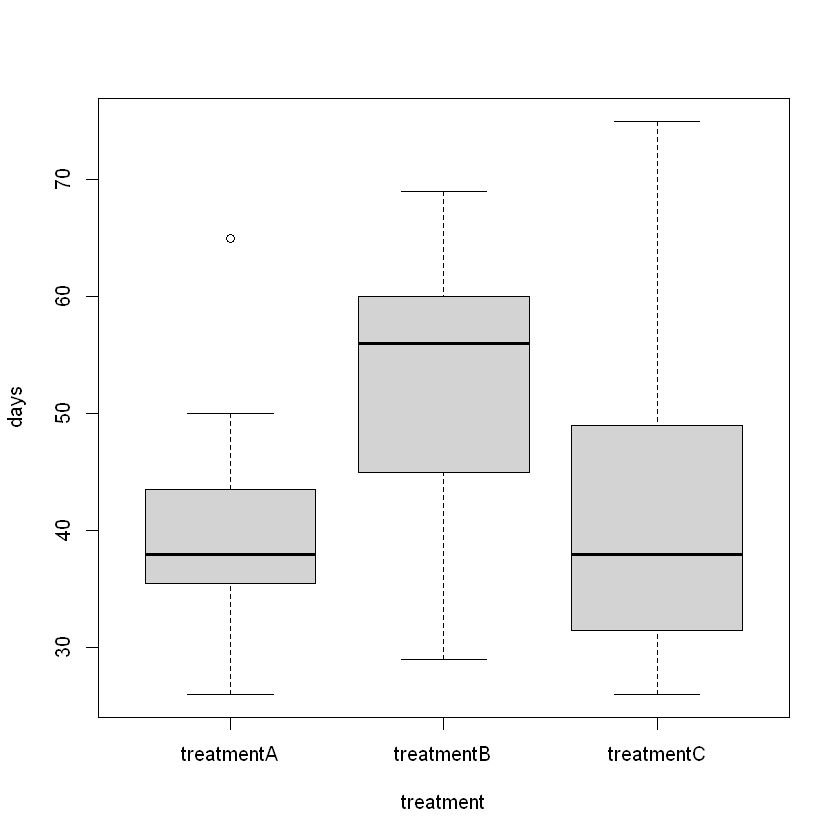

In [3]:
# Plot the boxplot representing days as a function of treatment
boxplot(days ~ treatment, data = asthma)

**Comment**:  
Given the boxplots, it seems that the B treatments is more efficient than the others two as the number of days before the next asthma attack is bigger.

Rather than testing the equality between each pair of means $\mu _A$ = $\mu _B$, $\mu _A$ = $\mu _C$, ..., $\mu _D$ = $\mu _C$ which would lead to analyzing n(n-1)=2 tests (with n = 3 the number of conditions). We will test
equality of all averages.

### 1.3 Testing conditions prior to analysis

Simultaneous testing of the equality of the means of several different samples
according to a controlled criterion can be performed using the method of one-factor controlled
variance method. To be possible, this test imposes certain conditions on the data:
- Each of the test samples must be normally distributed.
- The variances of all samples must be equal.

### 1.4 Testing sample normality

We will test the normality of the samples graphically and with the Shapiro-Wilk normality test.
normality test. 

It is important to note that normality must be tested on all three groups
groups: people who received treatments A, B and C respectively. First, we'll recreate
first recreate the 3 groups in R:

In [7]:
# Create the 3 new samples
treatA = asthma$days[asthma$treatment == "treatmentA"]
treatA

treatB = asthma$days[asthma$treatment == "treatmentB"]

treatC = asthma$days[asthma$treatment == "treatmentC"]


[1] 26 27 35 36 38 38 41 42 45 50 65

We will apply Shapiro's test for each of these three groups.

Specify hypotheses H0 and H1


H0 : The number of days before the next asthma attack follows a normal distribution

H1 : It doesn't follow a normal distribution


In [8]:
# Shapiro test
shapiro.test(treatA)
shapiro.test(treatB)
shapiro.test(treatC)


	Shapiro-Wilk normality test

data:  treatA
W = 0.92065, p-value = 0.3241



	Shapiro-Wilk normality test

data:  treatB
W = 0.95533, p-value = 0.5461



	Shapiro-Wilk normality test

data:  treatC
W = 0.91073, p-value = 0.1389


**Conclusion**:  
For all 3 treatments, we observe p >>> alpha = 0.05, so we can't reject H0, and the number of days for the three treatments follow a normal distribution.

Plot a graph showing the fit of the theoretical quantiles to the observed quantiles of the Normal distribution.

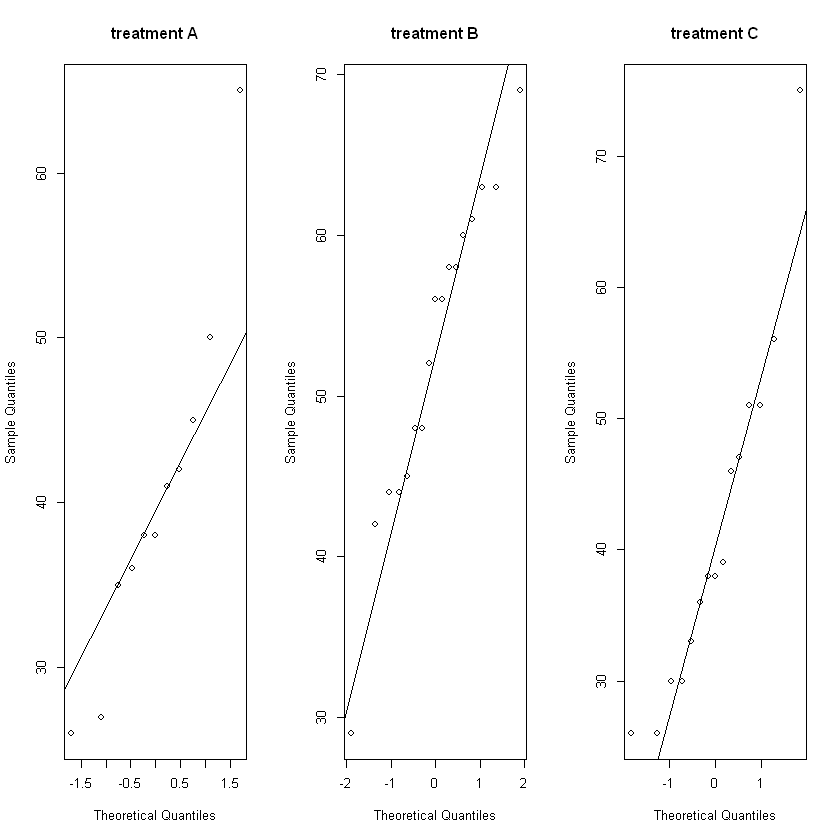

In [9]:
# Graphical parameters
par(mfrow = c(1, 3))

qqnorm(treatA, main = "treatment A")
qqline(treatA)

qqnorm(treatB, main = "treatment B")
qqline(treatB)

qqnorm(treatC, main = "treatment C")
qqline(treatC)

**Comment**:  
We similarly observe that the quantiles seem to follow a the ones of a normal distribution. As such, the three distributions seem normal.

### 1.5 Testing the equality of variances between different samples

To compare two variances, it is usual to use Fisher's test. When you want to
test the simultaneous equality of more than 2 variances, there is, as in the case of mean
comparison, there's a more appropriate test that doesn't require all comparisons to be made
comparisons. This is the Bartlett test of variance homogeneity.
The working hypotheses are :


- H0 : The variance of all the samples are equal
- H1 : At least one variance is different from the others

Let's perform Bartlett's test. For it you can use the function `bartlett.test()` which takes as first argument the formula as `quantitative_variable ~ group_variable` and second argument `df = XXX` the data frame name.

In [14]:
# Bartlett's test
head(asthma)
bartlett.test(days ~ treatment, data = asthma)

,days,treatment
,<int>,<chr>
1,26,treatmentA
2,27,treatmentA
3,35,treatmentA
4,36,treatmentA
5,38,treatmentA
6,38,treatmentA



	Bartlett test of homogeneity of variances

data:  days by treatment
Bartlett's K-squared = 1.1664, df = 2, p-value = 0.5581


**Conclusion** :  

We observe p = 0.56 >>> alpha = 0.05, so we can't reject H0, and as such the variance of all three treatments are equal.

### 1.6 Performing the one-factor ANOVA test

The ANOVA is then easily performed using the `aov()` function.

In [16]:
# Calculate anova
asthma_aov = aov(days ~ treatment, data = asthma)

# Display anova results
summary(asthma_aov)

            Df Sum Sq Mean Sq F value  Pr(>F)   
treatment    2   1427   713.4   5.467 0.00796 **
Residuals   40   5219   130.5                   
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

**Conclusion**: 

We observe p = 0.008 < alpha = 0.05, so we reject H0, and as such the difference in average days is driven by the treatment taken.


The `pairwise.t.test()` function is used to perform all Student's t-tests in pairs, in order to identify the averages
averages different from the other two, with correction for pvalues.

In [18]:
pairwise.t.test(asthma$days, asthma$treatment)


	Pairwise comparisons using t tests with pooled SD 

data:  asthma$days and asthma$treatment 

           treatmentA treatmentB
treatmentB 0.023      -         
treatmentC 0.794      0.023     

P value adjustment method: holm 

**Comment**:  
We observe that p = 0.023 < alpha = 0.05 between B and each other treatment, so we reject H0, which means that treatment B is different from A and from C.

### 1.7 Interpretation of the one-factor ANOVA table

The total variability of the data set can be broken down into two parts:

- variability due to the treatment on the time between two asthma attacks (inter-treatment variability)
- variability due to the individual (random variability)

This translates into :

**Total variability = Inter-treatment variability + Random variability**

If we return to the anova results table:

In [19]:
summary(asthma_aov)

            Df Sum Sq Mean Sq F value  Pr(>F)   
treatment    2   1427   713.4   5.467 0.00796 **
Residuals   40   5219   130.5                   
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

the `Sum Sq` column corresponds to the variability of the time variable between two asthma attacks,
it breaks down into two parts: 

- variability due to treatment is 1427 
- variability due to randomness (individual) is 5129 :

**Total variability = Inter-treatment variability + Random variability**

Total variability = 1427 + 5219 = 6646

the `Mean Sq` column corresponds to the variance in time between two asthma attacks: 

- the variance due to treatment is 713.4
- the variance due to randomness is 130.5.

To find out whether there is a difference between treatments on the time between two asthma attacks,
which can also be translated as “is there an effect of the treatment factor on the variable
between two asthma attacks?”, the principle is simple: 

the proportion of variation
The principle is simple: the proportion of variation due to the effect of the treatment is compared with the proportion of variation due to the (random) individual.

All that needs to be tested is whether the variance due to the (inter) factor is significantly greater than the residual variance (due to the individual).
by a Fisher-Snedecor test,

H0 : Inter variance = Random variance <=> no effect of factor A

H1 : Inter variance > Random variance <=> effect of factor A

$$ F=\frac{Variance_{Inter}}{Variance_{random}} $$

**Conclusion** : the inter variance is 5 times greater than the random variance, the pvalue of Fisher's test is equal to
is equal to 0.00796, i.e. less than 0.05, so H0 can be rejected.
at least one significant difference between the means.

## 2. Exercise

The effect of [ouabain](https://en.wikipedia.org/wiki/Ouabain) on myocardial noradrenaline levels is tested in rats. The
results are in the file `TD09_ouabain_noradrenaline.txt` in the `data/` folder. 

 `noradrenaline_level` is the noradrenaline content and `dose_ouabain` is the ouabain dose (from 0 to 1 mg/kg) injected.

Interpret the data and draw your conclusions. 


,noradrenaline_level,dose_ouabain
,<dbl>,<chr>
1,0.42,dose0
2,0.66,dose0
3,0.59,dose0
4,0.62,dose0
5,0.76,dose0
6,0.57,dose0


 noradrenaline_level dose_ouabain      
 Min.   :0.2500      Length:32         
 1st Qu.:0.4075      Class :character  
 Median :0.4950      Mode  :character  
 Mean   :0.5312                        
 3rd Qu.:0.6225                        
 Max.   :1.0300                        


   dose0 dose0.25  dose0.5    dose1 
       9        7        7        9 


	Shapiro-Wilk normality test

data:  dose_0
W = 0.8769, p-value = 0.1456



	Shapiro-Wilk normality test

data:  dose_025
W = 0.91389, p-value = 0.4235



	Shapiro-Wilk normality test

data:  dose_05
W = 0.96866, p-value = 0.8887



	Shapiro-Wilk normality test

data:  dose_1
W = 0.91006, p-value = 0.3163



	Bartlett test of homogeneity of variances

data:  noradrenaline_level by dose_ouabain
Bartlett's K-squared = 3.4056, df = 3, p-value = 0.3332


             Df Sum Sq Mean Sq F value  Pr(>F)   
dose_ouabain  3 0.4468 0.14893   5.349 0.00486 **
Residuals    28 0.7796 0.02784                   
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1


	Pairwise comparisons using t tests with pooled SD 

data:  ouabain$noradrenaline_level and ouabain$dose_ouabain 

         dose0 dose0.25 dose0.5
dose0.25 0.999 -        -      
dose0.5  0.203 0.203    -      
dose1    0.012 0.017    0.514  

P value adjustment method: holm 

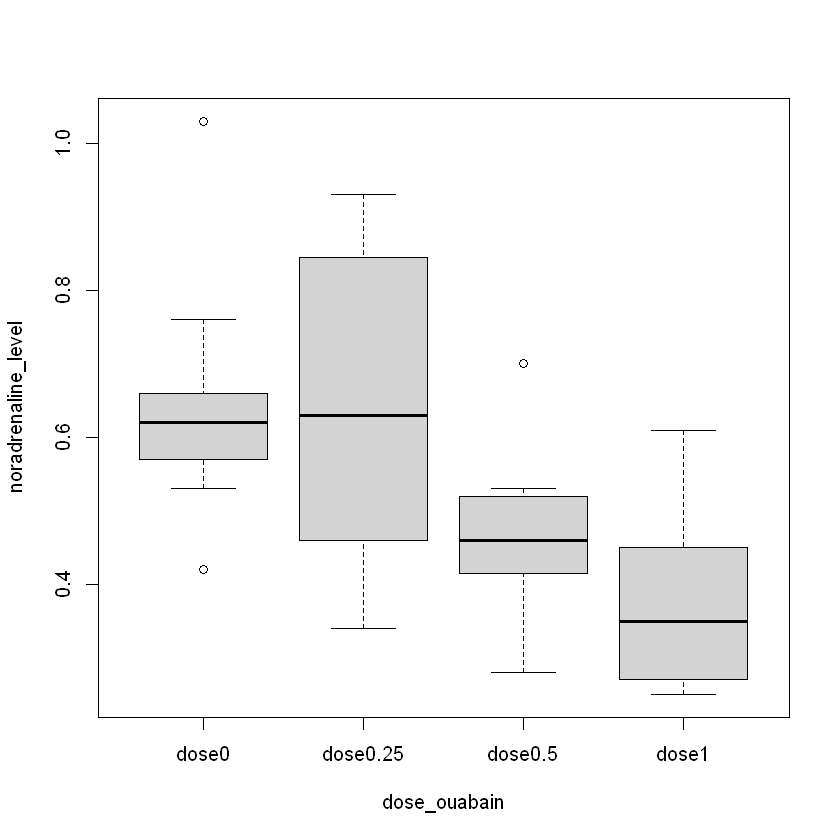

In [30]:
# Load data
ouabain = read.table("data/TD09_ouabain_noradrenaline.txt", header = TRUE)

# Data description
head(ouabain)
summary(ouabain)
table(ouabain$dose_ouabain)
boxplot(noradrenaline_level ~ dose_ouabain, data = ouabain)
# => given the boxplot it seems that increasing the dose of ouabain decreases noradrenaline levels
#    in particular from 0.5 mg⋅kg⁻¹ of ouabain

# Let's test this through an ANOVA
# We first need to check the assumpations

# Check normality
dose_0 = ouabain$noradrenaline_level[ouabain$dose_ouabain == "dose0"]
dose_025 = ouabain$noradrenaline_level[ouabain$dose_ouabain == "dose0.25"]
dose_05 = ouabain$noradrenaline_level[ouabain$dose_ouabain == "dose0.5"]
dose_1 = ouabain$noradrenaline_level[ouabain$dose_ouabain == "dose1"]

# Let's perform a Shapiro test with the same hypotheses as always
# H0: distribution is normal
# H1: distribution isn't normal
shapiro.test(dose_0)
shapiro.test(dose_025)
shapiro.test(dose_05)
shapiro.test(dose_1)
# => in all case we observe p >>> alpha = 0.05, so we can't reject H0, as such all of the distributions are normal

# Check equality of variance
# let's perform Bartlett's test with the following hypotheses
# H0: All the variances are equal
# H1: At least one variance is different from the others
bartlett.test(noradrenaline_level ~ dose_ouabain, data = ouabain)
# => we observe p = 0.33 >>> alpha = 0.05, so we can't reject H0, and as such the noradrine levels have the same variance across doses of ouabain.

# Let's perform the ANOVA
# With the following hypotheses
# H0: All average noradrenaline levels are different
# H1: at least one is different from the others
aov_ouabain = aov(noradrenaline_level ~ dose_ouabain, data = ouabain)
summary(aov_ouabain)
# => we observe p = 0.005 < alpha = 0.05, so we reject H0, and at least average noradrenaline level is different from the others

# Let's perform a pairwise t-test to check which one(s) is (or are) different
pairwise.t.test(ouabain$noradrenaline_level, ouabain$dose_ouabain)
# We observe p < 0.05 only for dose 1 compared to dose 0 and dose 0.25, so it seems that dose 1 is the one that is different.
# ==> As such, we could say that we need at least a dose of 1 mg⋅kg⁻¹ of ouabain to have an effect on the heart noradrenaline levels in rats.